# DAY3 실습 03 — 대응표본 t검정

In [1]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [2]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD_AX_S/data"
csv_path = os.path.join(data_folder, "Steel_industry_data.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

데이터 파일 : `Steel_industry_data.csv`
출처 : UCI Machine Learning Repository - [Steel Industry Energy Consumption](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption)

한 철강 공장의 2018년 전력 사용 기록이다. 15분마다 1건씩 기록되어 있다.

| 열 | 뜻 |
|---|---|
| `date` | 기록 시각 (일/월/연 시:분) |
| `Usage_kWh` | 15분 동안의 전력 사용량 (kWh) |
| `WeekStatus` | 평일(Weekday) · 주말(Weekend) |

**질문** : 평일 같은 날의 오전(08 ~12시)과 저녁(18 ~ 22시) 전력 사용량은 다른가?

**실습 전제** : 날짜 하나를 대상 하나로 보고, 같은 날의 두 시간대 사용량을 한 쌍으로 묶는다. 표본은 평일 중에서 무작위로 뽑은 날짜다. 여기서는 무작위로 뽑은 날짜별 관측값이 서로 독립이라고 가정한다. 실제 분석에서는 시간에 따른 의존성도 확인한다.

In [3]:
# 데이터 확인 : 행·열 수, 사용량 결측, 평일·주말 기록 수
print("행·열:", data.shape)
print("사용량 결측:", data["Usage_kWh"].isna().sum())     # 결측이 있으면 시간대 합계가 작게 계산된다
print(data["WeekStatus"].value_counts())                  # value_counts : 값별 개수

행·열: (35040, 11)
사용량 결측: 0
WeekStatus
Weekday    25056
Weekend     9984
Name: count, dtype: int64


## 1. 독립표본과 대응표본

두 값을 비교할 때는 먼저 두 값이 **서로 다른 대상**에서 나왔는지, **같은 대상**에서 나왔는지 확인한다.

| 구분 | 독립표본 | 대응표본 |
|---|---|---|
| 뜻 | 서로 다른 대상에서 얻은 두 집단 | 같은 대상을 두 번 측정했거나, 서로 짝지어진 관측값 |
| 예 | 설비 모델 A에서 측정한 값과 설비 모델 B에서 측정한 값 | 같은 설비의 정비 전·후 측정값, 같은 날의 오전·저녁 사용량 |
| 표본 수 | 두 집단의 수가 달라도 된다 | 짝이므로 두 측정값의 개수가 같아야 한다 |
| 분석 대상 | 두 집단 각각의 값 | 대상마다 계산한 **차이값** |
| 검정 | Welch t검정 | 대응표본 t검정 |


공식 문서 : [scipy.stats.ttest_rel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html)

## 2. 대응표본 t검정의 핵심 : 차이값

**대응표본 t검정**은 같은 대상에서 얻은 두 측정값의 차이값 d를 구하고, 그 차이값의 평균이 0과 다른지 검정하는 방법이다.

| 기호 | 뜻 |
|---|---|
| d | 대상마다 계산한 차이값 (예 : 후 − 전) |
| μd | 모집단의 평균 차이 |
| d̄ | 표본의 평균 차이 |

**분석 방법**

1) 대상마다 차이값 d를 계산한다. 뺄셈 순서(후 − 전)를 먼저 정하고 끝까지 같은 순서를 쓴다
2) 차이값의 정규성을 확인한다. 전·후 각각이 아니라 **차이값**의 분포를 본다
3) 차이값의 평균이 0과 다른지 t검정한다

**주의**
- 전·후 측정값의 짝을 유지한다. 같은 대상의 값을 같은 행에 둔다.
- 한쪽 값이 비어 있는 대상은 짝을 이룰 수 없으므로 분석에서 뺀다.

| 함수 | 기능 |
|---|---|
| `stats.ttest_rel(after, before)` | 대응표본 t검정. 차이값을 after − before 순서로 계산한다 |
| `결과.confidence_interval(confidence_level=0.95)` | 모집단 평균 차이 μd의 신뢰구간 |
| `stats.wilcoxon(after, before)` | 차이값의 정규성이 크게 어긋나고, 차이값의 분포가 대체로 좌우 대칭일 때 쓰는 비모수 검정 |

공식 문서 : [scipy.stats.ttest_rel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html) · [scipy.stats.shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html)

In [4]:
# [예제] 같은 직원 8명의 교육 전·후 작업시간(분)이 다른지 검정한다. 차이값 d = 후 − 전
# 귀무가설(H₀): 교육 전·후 작업시간의 모집단 평균 차이(후 − 전)는 0이다. (μd = 0)
# 대립가설(H₁): 교육 전·후 작업시간의 모집단 평균 차이(후 − 전)는 0이 아니다. (μd ≠ 0)
# 유의수준 α = 0.05, 양측
before = np.array([15, 14, 16, 13, 15, 17, 14, 16])   # 교육 전 작업시간 (직원 순서 고정)
after = np.array([12, 13, 12, 12, 13, 14, 12, 16])    # 교육 후 작업시간 (같은 직원 순서)

diff = after - before                                 # 1) 직원마다 차이값 계산 (후 − 전)
print("차이값:", diff)
print("평균 차이:", round(diff.mean(), 2), "분")

print("차이값 Shapiro-Wilk p값:", round(stats.shapiro(diff).pvalue, 4))   # 2) 차이값의 정규성 확인

result = stats.ttest_rel(after, before)               # 3) 대응표본 t검정. after − before 순서로 계산한다
ci = result.confidence_interval(confidence_level=0.95)   # 평균 차이 μd 의 95% 신뢰구간
print("t:", round(result.statistic, 2), "/ p값:", round(result.pvalue, 4), "/ 자유도:", result.df)
print("평균 차이 95% 신뢰구간:", round(ci.low, 2), "~", round(ci.high, 2), "분")

print("차이값의 일표본 t검정 p값:", round(stats.ttest_1samp(diff, 0).pvalue, 4))   # 차이값을 0과 비교한 일표본 t검정과 같은 결과

# [결과]
# - 차이값 −3, −1, −4, −1, −2, −3, −2, 0 → 평균 차이 −2분. 차이값 Shapiro-Wilk p = 0.8568 ≥ 0.05 → 대응표본 t검정을 쓴다
# - t = −4.32, p = 0.0035, 95% 신뢰구간 −3.09 ~ −0.91분
# - 통계적 결론 : p = 0.0035 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 교육 전·후 작업시간의 평균 차이는 0이 아니라고 볼 통계적 근거가 있으며, 표본에서 교육 후 평균 작업시간이 2분 감소했다 (95% 신뢰구간 −3.09 ~ −0.91분, n = 8)

차이값: [-3 -1 -4 -1 -2 -3 -2  0]
평균 차이: -2.0 분
차이값 Shapiro-Wilk p값: 0.8568
t: -4.32 / p값: 0.0035 / 자유도: 7
평균 차이 95% 신뢰구간: -3.09 ~ -0.91 분
차이값의 일표본 t검정 p값: 0.0035


### 뺄셈 순서와 결론 문장

`stats.ttest_rel(a, b)`는 차이값을 a − b 순서로 계산한다. 직원 8명 예제를 두 순서로 계산하면 다음과 같다.

| 항목 | `ttest_rel(after, before)` (후 − 전) | `ttest_rel(before, after)` (전 − 후) |
|---|---|---|
| t | −4.32 | +4.32 |
| p값 (양측) | 0.0035 | 0.0035 |
| 평균 차이 | −2분 | +2분 |
| 95% 신뢰구간 | −3.09 ~ −0.91분 | 0.91 ~ 3.09분 |
| 사실적 결론 | 표본에서 교육 후 평균 작업시간이 교육 전보다 2분 감소했다 | 표본에서 교육 전 평균 작업시간이 교육 후보다 2분 길었다 |
| "교육 후 줄었는가" 단측검정 | `alternative="less"` (후 − 전 < 0) | `alternative="greater"` (전 − 후 > 0) |

- 양측검정에서는 순서를 바꿔도 p값과 결론의 내용이 같고, 부호와 문장 표현만 달라진다.
- 단측검정에서는 `alternative` 방향을 뺄셈 순서에 맞춘다.
- 뺄셈 순서는 질문 문장에 맞춰 먼저 정한다. 예) "교육 후 줄었는가" → 후 − 전, `alternative="less"`

공식 문서 : [scipy.stats.ttest_rel (alternative)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html)

In [5]:
# [예제] 질문 : 교육 후 작업시간이 줄었는가? 같은 질문을 두 가지 뺄셈 순서로 단측검정한다
# 유의수준 α = 0.05, 단측

# 후 − 전 순서
# 귀무가설(H₀): 교육 전·후 작업시간의 모집단 평균 차이(후 − 전)는 0 이상이다. (μd ≥ 0)
# 대립가설(H₁): 교육 전·후 작업시간의 모집단 평균 차이(후 − 전)는 0보다 작다. (μd < 0)
print("평균 차이(후 − 전):", round((after - before).mean(), 2), "분")          # 표본의 평균 차이
less_result = stats.ttest_rel(after, before, alternative="less")          # 후 − 전 이 0보다 작은지 검정
print("후 − 전, less → t:", round(less_result.statistic, 2), "/ p값:", round(less_result.pvalue, 4))

# 전 − 후 순서
# 귀무가설(H₀): 교육 전·후 작업시간의 모집단 평균 차이(전 − 후)는 0 이하다. (μd ≤ 0)
# 대립가설(H₁): 교육 전·후 작업시간의 모집단 평균 차이(전 − 후)는 0보다 크다. (μd > 0)
print("평균 차이(전 − 후):", round((before - after).mean(), 2), "분")          # 표본의 평균 차이
greater_result = stats.ttest_rel(before, after, alternative="greater")    # 전 − 후 가 0보다 큰지 검정
print("전 − 후, greater → t:", round(greater_result.statistic, 2), "/ p값:", round(greater_result.pvalue, 4))

# [결과]
# - 후 − 전 순서 (less) : 평균 차이 −2분, t = −4.32, p = 0.0017
#   통계적 결론 : p = 0.0017 < 0.05 이므로 귀무가설을 기각한다
#   사실적 결론 : 교육 전·후 작업시간의 평균 차이(후 − 전)는 0보다 작다고 볼 통계적 근거가 있다. 표본에서 교육 후 작업시간이 교육 전보다 평균 2분 줄었다 (n = 8)
# - 전 − 후 순서 (greater) : 평균 차이 +2분, t = +4.32, p = 0.0017
#   통계적 결론 : p = 0.0017 < 0.05 이므로 귀무가설을 기각한다
#   사실적 결론 : 교육 전·후 작업시간의 평균 차이(전 − 후)는 0보다 크다고 볼 통계적 근거가 있다. 표본에서 교육 전 작업시간이 교육 후보다 평균 2분 길었다 (n = 8)
# - 두 검정은 같은 질문(교육 후 줄었는가)을 뺄셈 순서만 바꿔 표현한 것이다. 그래서 p값이 같고, 결론이 담은 사실도 같다

평균 차이(후 − 전): -2.0 분
후 − 전, less → t: -4.32 / p값: 0.0017
평균 차이(전 − 후): 2.0 분
전 − 후, greater → t: 4.32 / p값: 0.0017


## 3. 날짜별 확인

15분 단위 기록을 **날짜 하나에 한 행**인 표로 바꾼다. 각 행에는 그날의 오전 사용량과 저녁 사용량을 나란히 둔다.

| 시간대 | 포함하는 기록 | 기록 수 |
|---|---|---|
| 오전 (08~12시) | 시각의 시(hour)가 8, 9, 10, 11인 기록 | 하루 16건 |
| 저녁 (18~22시) | 시각의 시(hour)가 18, 19, 20, 21인 기록 | 하루 16건 |


공식 문서 : [pandas.to_datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) · [Series.dt](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.html) · [Series.between](https://pandas.pydata.org/docs/reference/api/pandas.Series.between.html) · [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)

In [6]:
# [예제] 평일 날짜별로 오전(08~12시) · 저녁(18~22시) 사용량 합계를 구해 짝 자료 표를 만든다
data["date"] = pd.to_datetime(data["date"], format="%d/%m/%Y %H:%M")   # 문자열 → 날짜·시각 형식
data["day"] = data["date"].dt.date                                      # 날짜 (짝을 묶는 기준)
data["hour"] = data["date"].dt.hour                                     # 시 (0 ~ 23)

weekday = data.loc[data["WeekStatus"] == "Weekday"]                     # 평일 기록만

morning = weekday.loc[weekday["hour"].between(8, 11)].groupby("day")["Usage_kWh"].sum()    # 날짜별 오전 사용량 합계
evening = weekday.loc[weekday["hour"].between(18, 21)].groupby("day")["Usage_kWh"].sum()   # 날짜별 저녁 사용량 합계

paired = pd.DataFrame({"morning": morning, "evening": evening}).dropna()   # 같은 날짜끼리 한 행에 나란히. 한쪽이 없는 날은 뺀다
print("날짜 수:", len(paired))
print(paired.head())

# [결과]
# - 평일 261일, 날짜마다 오전·저녁 사용량이 한 행에 나란히 있다. 이 한 행이 한 쌍이다

날짜 수: 261
            morning  evening
day                         
2018-01-01    59.48    60.54
2018-01-02  1028.88   482.53
2018-01-03  1180.73   527.26
2018-01-04  1753.45   733.73
2018-01-05  1726.93   718.85


## 4. 대응표본 t검정 실습 : 오전과 저녁

평일 자료 261일에서 20일을 뽑아 4단계로 검정한다. 차이값은 **저녁 − 오전**으로 정한다.

1) 가설 설정
   - 귀무가설(H₀): 평일 저녁과 오전 전력 사용량의 모집단 평균 차이(저녁 − 오전)는 0이다. (μd = 0)
   - 대립가설(H₁): 평일 저녁과 오전 전력 사용량의 모집단 평균 차이(저녁 − 오전)는 0이 아니다. (μd ≠ 0)
2) 유의수준 : α = 0.05, 양측
3) 정규성 확인 → 검정 : 차이값의 히스토그램 · Q-Q 플롯 · Shapiro-Wilk 검정 → `stats.ttest_rel`
4) 결과 도출 : p값, 평균 차이, 신뢰구간으로 두 줄 결론을 쓴다

공식 문서 : [scipy.stats.ttest_rel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html) · [scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html)

In [7]:
# [실습]
# 상황 : 대응표본 t검정은 차이값의 정규성을 확인한다. 자료 261일에서 20일을 뽑아 차이값의 분포를 먼저 본다.
#        귀무가설(H₀): 차이값(저녁 − 오전)은 정규분포를 따른다.
#        대립가설(H₁): 차이값(저녁 − 오전)은 정규분포를 따르지 않는다. (α = 0.05)
# paired 에서 20일(random_state=0)을 뽑아 sample_days 로 저장하고, 차이값 day_diff(저녁 − 오전)를 만드시오.
# 차이값의 히스토그램과 Q-Q 플롯을 나란히 그리고, Shapiro-Wilk 검정의 p값을 구하시오.
sample_days = paired.sample(n=20, replace=False, random_state=0)
day_diff = sample_days["evening"] - sample_days["morning"]
print("Shapiro-Wilk p값:", round(stats.shapiro(day_diff).pvalue, 4))

Shapiro-Wilk p값: 0.7435


In [8]:
# [실습]
# 상황 : 차이값의 정규성이 크게 어긋나지 않으므로 대응표본 t검정으로 오전과 저녁의 사용량을 비교한다.
#        귀무가설(H₀): 평일 저녁과 오전 전력 사용량의 모집단 평균 차이(저녁 − 오전)는 0이다. (μd = 0)
#        대립가설(H₁): 평일 저녁과 오전 전력 사용량의 모집단 평균 차이(저녁 − 오전)는 0이 아니다. (μd ≠ 0)
#        유의수준 α = 0.05, 양측
# sample_days 로 오전 · 저녁 평균 사용량과 평균 차이를 구하고, 대응표본 t검정의 t, p값, 자유도와 평균 차이의 95% 신뢰구간을 구하시오.

print("오전 평균:", round(sample_days["morning"].mean(), 1), "kWh / 저녁 평균:", round(sample_days["evening"].mean(), 1), "kWh")
print("평균 차이(저녁 − 오전):", round(day_diff.mean(), 1), "kWh")

day_result = stats.ttest_rel(sample_days["evening"], sample_days["morning"])   # 저녁 − 오전 순서
day_ci = day_result.confidence_interval(confidence_level=0.95)
print("t:", round(day_result.statistic, 3), "/ p값:", round(day_result.pvalue, 4), "/ 자유도:", day_result.df)
print("평균 차이 95% 신뢰구간:", round(day_ci.low, 1), "~", round(day_ci.high, 1), "kWh")


오전 평균: 911.2 kWh / 저녁 평균: 694.1 kWh
평균 차이(저녁 − 오전): -217.1 kWh
t: -3.492 / p값: 0.0024 / 자유도: 19
평균 차이 95% 신뢰구간: -347.2 ~ -87.0 kWh


In [9]:
# [실습]
# 상황 : 위 검정 결과를 보고서에 두 줄로 정리한다.
# 아래 결론 문장의 빈칸을 채우시오.
#    통계적 결론 : p = ___ ___ 0.05 이므로 귀무가설을 ___________.
#    사실적 결론 : 평일 저녁과 오전 전력 사용량의 평균 차이는 0이 아니라고 볼 통계적 근거가 ______, 표본에서 저녁 사용량이 오전보다 평균 ___ kWh ______ (95% 신뢰구간 ___ ~ ___ kWh, n = 20일).

#  통계적 결론 : p = 0.0024 < 0.05 이므로 귀무가설을 기각한다.
#  사실적 결론 : 평일 저녁과 오전 전력 사용량의 평균 차이는 0이 아니라고 볼 통계적 근거가 있으며,
# 표본에서 저녁 사용량이 오전보다 평균 217.1 kWh 적었다 (95% 신뢰구간 −347.2 ~ −87.0 kWh, n = 20일).

In [10]:
# [실습]
# 상황 : 설비 담당자는 저녁 사용량이 오전보다 적은지 알고 싶다. 같은 20일(sample_days)로 단측검정을 한다.
#        귀무가설(H₀): 평일 저녁과 오전 전력 사용량의 모집단 평균 차이(저녁 − 오전)는 0 이상이다. (μd ≥ 0)
#        대립가설(H₁): 평일 저녁과 오전 전력 사용량의 모집단 평균 차이(저녁 − 오전)는 0보다 작다. (μd < 0) # 저녁사용량이 오전 보다 작다
#        유의수준 α = 0.05, 단측
# 평균 차이(저녁 − 오전)를 구하고, 뺄셈 순서에 맞는 alternative 를 넣어 대응표본 t검정의 t와 p값을 구한 뒤 통계적 결론과 사실적 결론을 쓰시오.

print("평균 차이(저녁 − 오전):", round(day_diff.mean(), 1), "kWh")                                 # 표본의 평균 차이
day_less = stats.ttest_rel(sample_days["evening"], sample_days["morning"], alternative="less")   # 저녁 − 오전 < 0
print("t:", round(day_less.statistic, 3), "/ 단측 p값:", round(day_less.pvalue, 4))
# - 평균 차이 −217.1 kWh, t = −3.492, p = 0.0012
# - 통계적 결론 : p = 0.0012 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 평일 저녁과 오전 전력 사용량의 평균 차이(저녁 − 오전)는 0보다 작다고 볼 통계적 근거가 있다. 표본에서 저녁 사용량이 오전보다 평균 217.1 kWh 적었다 (n = 20일)

평균 차이(저녁 − 오전): -217.1 kWh
t: -3.492 / 단측 p값: 0.0012


## 5. 차이값의 정규성이 크게 어긋날 때 : 비모수 검정 (Wilcoxon 부호순위검정)

차이값의 정규성이 크게 어긋나고 **차이값 분포가 대체로 대칭**이라면 **Wilcoxon 부호순위검정**을 고려할 수 있다. 단, 정규성 검정 p값만으로 검정을 결정하지 않으며 분석 목적과 표본의 분포를 함께 살핀다. 일표본에서 쓴 검정과 같은 방법을 차이값에 적용한다.

| 항목 | 내용 |
|---|---|
| 함수 | `stats.wilcoxon(after, before)` : 차이값을 after − before 순서로 계산한다 |
| 사용 조건 | 차이값의 분포가 **대체로 좌우 대칭**이다. 히스토그램(값의 배열)에서 중심 양쪽의 모양이 비슷한지로 확인한다.  |
| 비교 대상 | 차이값의 분포가 0을 중심으로 대칭인지 검정한다. 차이값 분포의 대칭성을 전제로 하면 중앙값을 기준으로 해석할 수 있다 |
| 가설 형식 | 귀무가설(H₀): 차이값의 분포는 0을 중심으로 대칭이다.<br>대립가설(H₁): 차이값의 분포는 0을 중심으로 대칭이 아니다. |
| 결과 해석 | 기본적으로 0을 중심으로 한 차이값 분포의 대칭성에 대해 결론을 쓴다. 차이값 분포가 대체로 대칭이라는 전제가 적절할 때 중앙값 차이로도 해석할 수 있다 |

중앙값으로 설명할 때는 차이값의 분포가 대체로 대칭이라는 가정이 필요하다. 히스토그램만으로 대칭성을 확정할 수 없으므로 분포 형태, 극단값, 분석 목적을 함께 고려한다. 차이값 분포가 심하게 비대칭이면 Wilcoxon 결과를 단순한 중앙값 검정으로 해석하지 않는다.

공식 문서 : [scipy.stats.wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html)

/tmp/ipykernel_1751/2159279768.py:18: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumGothic.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumGothic.
  fig.canvas.print_figure(bytes_io, **kw)


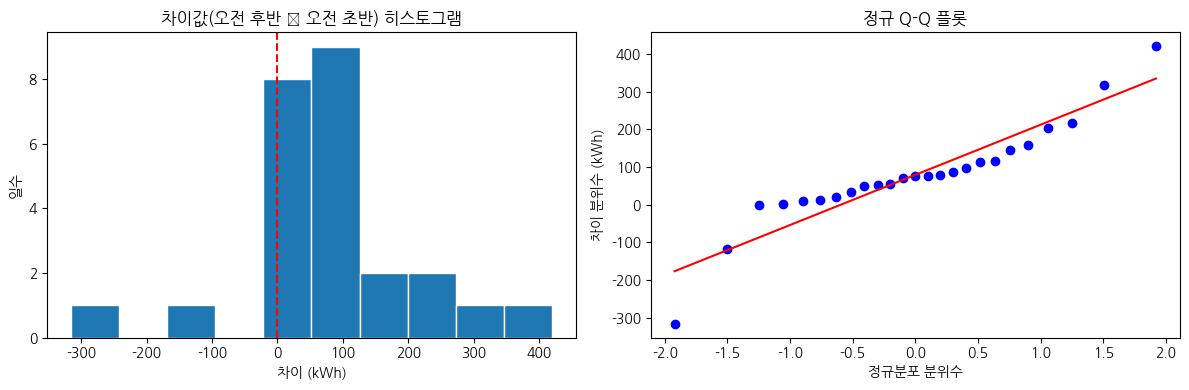

평균 차이: 79.0 kWh / 차이의 중앙값: 75.1 kWh
차이값 Shapiro-Wilk p값: 0.0221
차이가 양수인 날: 22 / 음수인 날: 3
Wilcoxon 통계량: 42.0 / p값: 0.00063


In [11]:
# [예제] 평일 같은 날의 오전 초반(08~10시)과 오전 후반(10~12시) 사용량을 비교한다. 차이값 = 오전 후반 − 오전 초반
# 귀무가설(H₀): 전력 사용량 차이(오전 후반 − 오전 초반)의 분포는 0을 중심으로 대칭이다.
# 대립가설(H₁): 전력 사용량 차이(오전 후반 − 오전 초반)의 분포는 0을 중심으로 대칭이 아니다.
# 유의수준 α = 0.05, 양측
early = weekday.loc[weekday["hour"].between(8, 9)].groupby("day")["Usage_kWh"].sum()      # 날짜별 08~10시 합계
late = weekday.loc[weekday["hour"].between(10, 11)].groupby("day")["Usage_kWh"].sum()     # 날짜별 10~12시 합계
morning_paired = pd.DataFrame({"early": early, "late": late}).dropna()

morning_days = morning_paired.sample(n=25, replace=False, random_state=25)   # 25일 표본
morning_diff = morning_days["late"] - morning_days["early"]                   # 차이값 = 오전 후반 − 오전 초반

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(morning_diff, bins=10, edgecolor="white")                        # 좌우가 대체로 대칭인지 확인
axes[0].axvline(0, color="red", linestyle="--")                               # 차이 0 위치
axes[0].set(title="차이값(오전 후반 − 오전 초반) 히스토그램", xlabel="차이 (kWh)", ylabel="일수")
stats.probplot(morning_diff, dist="norm", plot=axes[1])                       # 정규성 확인
axes[1].set(title="정규 Q-Q 플롯", xlabel="정규분포 분위수", ylabel="차이 분위수 (kWh)")
plt.tight_layout()
plt.show()

print("평균 차이:", round(morning_diff.mean(), 1), "kWh / 차이의 중앙값:", round(morning_diff.median(), 1), "kWh")   # 참고 지표 : 대칭이면 두 값이 가깝다 (가깝다고 대칭인 것은 아니다)
print("차이값 Shapiro-Wilk p값:", round(stats.shapiro(morning_diff).pvalue, 4))
print("차이가 양수인 날:", (morning_diff > 0).sum(), "/ 음수인 날:", (morning_diff < 0).sum())

morning_result = stats.wilcoxon(morning_days["late"], morning_days["early"])  # 오전 후반 − 오전 초반 순서
print("Wilcoxon 통계량:", morning_result.statistic, "/ p값:", round(morning_result.pvalue, 5))

# [결과]
# - 차이값 Shapiro-Wilk p = 0.0221 < 0.05. 가운데에 몰려 있고 양쪽에 멀리 떨어진 날이 있다 → 정규성이 어긋난다
# - 히스토그램에서 분포의 모양을 살피고 차이값 분포의 대칭성 가정이 적절한지 검토한다. 평균과 중앙값이 가깝다는 사실만으로 대칭성을 확정하지 않는다
# - 양수 22일, 음수 3일, p = 0.00063
# - 통계적 결론 : p = 0.00063 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 전력 사용량 차이값의 분포가 0을 중심으로 대칭이라는 귀무가설에 반하는 근거가 있다. 차이값 분포의 대칭성 가정이 적절하다면 중앙값이 0과 다르다고 해석할 수 있다. 표본에서는 오전 후반 사용량이 더 많았다 (차이의 중앙값 75.1 kWh, 25일 중 22일 증가)

## 6. 정리 : 대응표본 비교

| 단계 | 내용 |
|---|---|
| 1) 구조 확인 | 같은 대상을 두 번 측정했거나 짝지어진 값인지 확인한다. 짝이 맞는 행끼리 비교한다 |
| 2) 차이값 | 뺄셈 순서(예 : 후 − 전)를 정하고 대상마다 차이값을 계산한다 |
| 3) 가설 | 귀무가설(H₀): 모집단 평균 차이는 0이다. (μd = 0) / 대립가설(H₁): 모집단 평균 차이는 0이 아니다. (μd ≠ 0) |
| 4) 정규성 확인 | 차이값의 히스토그램 · Q-Q 플롯 · Shapiro-Wilk 검정 |
| 5) 검정 | 평균 차이를 검정하고 차이값 정규성 가정이 적절하면 `stats.ttest_rel(after, before)`를 고려한다. 차이값이 비정규적이고 대체로 대칭인 분포라면 `stats.wilcoxon(after, before)`를 고려한다. 심한 비대칭에서는 검정의 가정과 분석 목적을 다시 검토한다 |
| 6) 결론 | 통계적 결론과 사실적 결론. 차이의 방향 · 크기 · 신뢰구간 · 쌍의 수를 함께 쓴다 |

### 해석 시 유의점

| 항목 | 해석 기준 |
|---|---|
| 대응표본 t검정 | 대상별 차이값의 평균이 0인지 검정하는 일표본 t검정과 같다 |
| 정규성 확인 대상 | 전·후 측정값 각각이 아니라 차이값의 분포를 확인한다 |
| 뺄셈 순서 | `ttest_rel(a, b)`는 차이를 a − b로 계산한다. 순서를 바꾸면 t값·평균 차이·신뢰구간의 부호가 바뀌므로 결론 문장의 방향을 확인한다. 단측검정에서는 `alternative` 방향을 뺄셈 순서에 맞춘다 |
| 표본 크기 n | 측정값의 개수가 아니라 쌍의 수로 보고한다 |
| 검정 선택 | 검정은 정규성 p값 하나로 정하지 않는다. 먼저 비교할 대상(평균인지, 중앙값·분포인지)을 정하고, 표본 크기 · 분포 모양 · 극단값을 함께 본다. |
| Wilcoxon 부호순위검정 | 공식 귀무가설은 차이값의 분포가 0을 중심으로 대칭이라는 것이다. 차이값 분포의 대칭성 가정이 적절할 때 중앙값을 기준으로 해석할 수 있다 |

공식 문서 : [scipy.stats.ttest_rel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html) · [scipy.stats.wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html)